# 11 — Evaluación, explicabilidad y cierre del modelo

Objetivos:
- Consolidar las métricas temporales de la logística con recuentos sin recalibración adicional.
- Estimar intervalos bootstrap del 95 % por estudiante.
- Ajustar el pipeline elegido con todos los registros de modelado disponibles.
- Explicar su comportamiento global y tres casos individuales.
- Guardar el pipeline, las dieciséis features y sus metadatos de forma reproducible.

**Dos usos separados:** las métricas proceden de las predicciones temporales fuera de muestra de los notebooks 09–10. El modelo ajustado con todos los datos se utiliza para preparar el artefacto y explicar ejemplos; no se evalúa su desempeño con sus propios datos de entrenamiento.

Se conserva el corte 0,50 como referencia, no como umbral operativo validado. Los años ya fueron inspeccionados y los intervalos no convierten la evaluación exploratoria en un test independiente.

Las explicaciones se calculan sobre observaciones de 2025 para estimar riesgo en 2026–2027. No se les asigna un resultado real que todavía no puede verificarse con dos años completos de seguimiento.

Ejecutar todas las celdas en orden desde un kernel nuevo. No se sube el modelo a Hugging Face ni se despliega en Railway.


## 1. Entorno y parámetros de cierre

Se utilizan las mismas dependencias del pipeline. El método analítico de explicación lineal no requiere instalar la librería shap. Los archivos se escribirán únicamente en las últimas secciones.


In [1]:
import os
import sys
import json
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import joblib
import sklearn
import scipy

from scipy.special import expit
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    brier_score_loss,
    log_loss,
)

PROJ_ROOT = Path.cwd()

if PROJ_ROOT.name == "notebooks":
    PROJ_ROOT = PROJ_ROOT.parent

assert (PROJ_ROOT / "src").is_dir()
os.chdir(PROJ_ROOT)

if str(PROJ_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT))

from src.data.load_data import load_processed, load_raw
from src.features.build_features import FEATURES_COLS, agregar_features

with open("configs/config.yaml", encoding="utf-8") as archivo:
    config = yaml.safe_load(archivo)

SEED = int(config["random_seed"])
VENTANA = int(config["target"]["ventana_anios"])
CIERRE_DATOS = int(config["target"]["censurar_hasta"])
ANIOS_EVALUACION = [2022, 2023]
UMBRAL_REFERENCIA = 0.50
N_BOOTSTRAP = 1000
NIVEL_CONFIANZA = 0.95
VERSION_MODELO = "logistica-recuentos-v1"

CLAVES = ["id_alumno", "anio_academico"]
RECUENTOS = [
    "asignaturas_cursadas",
    "inscripciones_finales",
    "finales_aprobados",
]
COLUMNAS_MODELO = list(FEATURES_COLS) + RECUENTOS

CARPETA_REPORTES = PROJ_ROOT / "reports"
CARPETA_FIGURAS = CARPETA_REPORTES / "figures"
CARPETA_MODELOS = PROJ_ROOT / "models"
RUTA_MODELO = CARPETA_MODELOS / "modelo_final.joblib"

figuras = {}

print("Modelo:", VERSION_MODELO)
print("Predictores:", len(COLUMNAS_MODELO))
print("Cierre de seguimiento:", CIERRE_DATOS)
print("Bootstrap por estudiante:", N_BOOTSTRAP)


Modelo: logistica-recuentos-v1
Predictores: 16
Cierre de seguimiento: 2025
Bootstrap por estudiante: 1000


## 2. Predicciones de evaluación fuera de muestra

Se selecciona exclusivamente la variante sin calibrar. Cada estudiante puede aparecer en distintos años, pero tiene una sola observación dentro de cada año. Las etiquetas deben coincidir con el dataset preparado.


In [2]:
ruta_predicciones = CARPETA_REPORTES / "calibracion_predicciones.csv"
assert ruta_predicciones.is_file(), "Primero ejecutá el notebook 10."

evaluacion = pd.read_csv(ruta_predicciones)
evaluacion = evaluacion.loc[
    evaluacion["modelo"].eq("logistica_recuentos")
    & evaluacion["variante"].eq("sin_calibrar")
    & evaluacion["anio_academico"].isin(ANIOS_EVALUACION)
].copy()

assert not evaluacion.empty
assert not evaluacion.duplicated(CLAVES).any()
assert evaluacion[[
    "id_alumno", "anio_academico", "fold",
    "abandono_real", "probabilidad_abandono", "ultimo_anio_train",
]].notna().all().all()
assert evaluacion["abandono_real"].isin([0, 1]).all()
assert evaluacion["probabilidad_abandono"].between(0, 1).all()
assert (
    evaluacion["ultimo_anio_train"] + VENTANA
).le(evaluacion["anio_academico"]).all()

df_modelado = (
    load_processed()
    .sort_values(CLAVES)
    .reset_index(drop=True)
)
assert not df_modelado.duplicated(CLAVES).any()

verificacion = evaluacion.merge(
    df_modelado[CLAVES + ["abandono"]],
    on=CLAVES,
    how="left",
    validate="one_to_one",
)
assert verificacion["abandono"].notna().all()
assert verificacion["abandono_real"].eq(verificacion["abandono"]).all()

display(
    evaluacion.groupby("anio_academico").agg(
        registros=("id_alumno", "size"),
        estudiantes=("id_alumno", "nunique"),
        positivos=("abandono_real", "sum"),
    )
)


,registros,estudiantes,positivos
anio_academico,,,
2022,421,421,116
2023,589,589,152


## 3. Métricas observadas

Se calculan sobre las predicciones temporales agrupadas de cada año. Precisión y recall usan el corte de referencia. No se calculan métricas de desempeño con el modelo que posteriormente se ajustará con todos los registros.


In [3]:
def calcular_metricas(real, prob):
    real = np.asarray(real, dtype=int)
    prob = np.asarray(prob, dtype=float)
    pred = prob >= UMBRAL_REFERENCIA

    return {
        "roc_auc": roc_auc_score(real, prob),
        "average_precision": average_precision_score(real, prob),
        "precision": precision_score(real, pred, zero_division=0),
        "recall": recall_score(real, pred, zero_division=0),
        "brier": brier_score_loss(real, prob),
        "log_loss": log_loss(real, prob, labels=[0, 1]),
    }


filas = []
for anio, grupo in evaluacion.groupby("anio_academico"):
    filas.append({
        "anio_evaluacion": int(anio),
        "registros": len(grupo),
        "estudiantes": grupo["id_alumno"].nunique(),
        **calcular_metricas(
            grupo["abandono_real"],
            grupo["probabilidad_abandono"],
        ),
    })

metricas_observadas = pd.DataFrame(filas)
display(metricas_observadas.round(4))


,anio_evaluacion,registros,estudiantes,roc_auc,average_precision,precision,recall,brier,log_loss
0,2022,421,421,0.8410,0.7246,0.7889,0.6121,0.1295,0.4184
1,2023,589,589,0.7782,0.6381,0.7045,0.4079,0.1487,0.4750


## 4. Intervalos bootstrap por estudiante

Se remuestrean estudiantes con reemplazo y se conservan juntos sus registros dentro de cada año. Aquí hay una observación por alumno y año, por lo que coincide con remuestrear filas dentro del año. No se reentrena el modelo: los intervalos son condicionales a las predicciones guardadas y no incorporan toda la incertidumbre del entrenamiento, la selección de modelos o los cambios futuros de población.


In [4]:
def bootstrap_por_estudiante(grupo, semilla):
    grupo = grupo.reset_index(drop=True)
    ids = grupo["id_alumno"].to_numpy()
    reales = grupo["abandono_real"].to_numpy(dtype=int)
    probabilidades = grupo["probabilidad_abandono"].to_numpy(dtype=float)

    estudiantes = pd.unique(ids)
    bloques = [
        np.flatnonzero(ids == estudiante)
        for estudiante in estudiantes
    ]

    rng = np.random.default_rng(semilla)
    muestras = []

    for repeticion in range(N_BOOTSTRAP):
        seleccion = rng.integers(
            0, len(bloques), size=len(bloques)
        )
        indices = np.concatenate([
            bloques[posicion] for posicion in seleccion
        ])

        real = reales[indices]
        if np.unique(real).size < 2:
            continue

        muestras.append({
            "repeticion": repeticion,
            **calcular_metricas(real, probabilidades[indices]),
        })

    assert len(muestras) >= 0.95 * N_BOOTSTRAP, (
        "Hay demasiadas muestras sin ambas clases."
    )
    return pd.DataFrame(muestras)


bloques_bootstrap = []
filas_intervalos = []
alpha = (1 - NIVEL_CONFIANZA) / 2

for anio, grupo in evaluacion.groupby("anio_academico"):
    muestras = bootstrap_por_estudiante(
        grupo, semilla=SEED + int(anio)
    )
    muestras["anio_evaluacion"] = int(anio)
    bloques_bootstrap.append(muestras)

    observadas = calcular_metricas(
        grupo["abandono_real"],
        grupo["probabilidad_abandono"],
    )

    for metrica, valor in observadas.items():
        inferior, superior = muestras[metrica].quantile(
            [alpha, 1 - alpha]
        ).to_numpy()

        filas_intervalos.append({
            "anio_evaluacion": int(anio),
            "modelo": "logistica_recuentos",
            "metrica": metrica,
            "valor": valor,
            "ic95_inferior": inferior,
            "ic95_superior": superior,
            "bootstrap_validos": len(muestras),
            "umbral_referencia": UMBRAL_REFERENCIA,
        })

muestras_bootstrap = pd.concat(
    bloques_bootstrap, ignore_index=True
)
metricas_finales = pd.DataFrame(filas_intervalos)

display(metricas_finales.round(4))


,anio_evaluacion,modelo,metrica,valor,ic95_inferior,ic95_superior,bootstrap_validos,umbral_referencia
0,2022,logistica_recuentos,roc_auc,0.8410,0.7917,0.8828,1000,0.5
1,2022,logistica_recuentos,average_precision,0.7246,0.6381,0.8099,1000,0.5
2,2022,logistica_recuentos,precision,0.7889,0.6989,0.8721,1000,0.5
3,2022,logistica_recuentos,recall,0.6121,0.5257,0.6983,1000,0.5
4,2022,logistica_recuentos,brier,0.1295,0.1111,0.1498,1000,0.5
5,2022,logistica_recuentos,log_loss,0.4184,0.3694,0.4750,1000,0.5
6,2023,logistica_recuentos,roc_auc,0.7782,0.7341,0.8187,1000,0.5
7,2023,logistica_recuentos,average_precision,0.6381,0.5648,0.7133,1000,0.5
8,2023,logistica_recuentos,precision,0.7045,0.6111,0.8065,1000,0.5
9,2023,logistica_recuentos,recall,0.4079,0.3289,0.4824,1000,0.5


## 5. Visualización de los intervalos

Los intervalos son percentiles bootstrap del 95 %, no garantías de desempeño futuro ni una prueba independiente después de seleccionar el modelo.


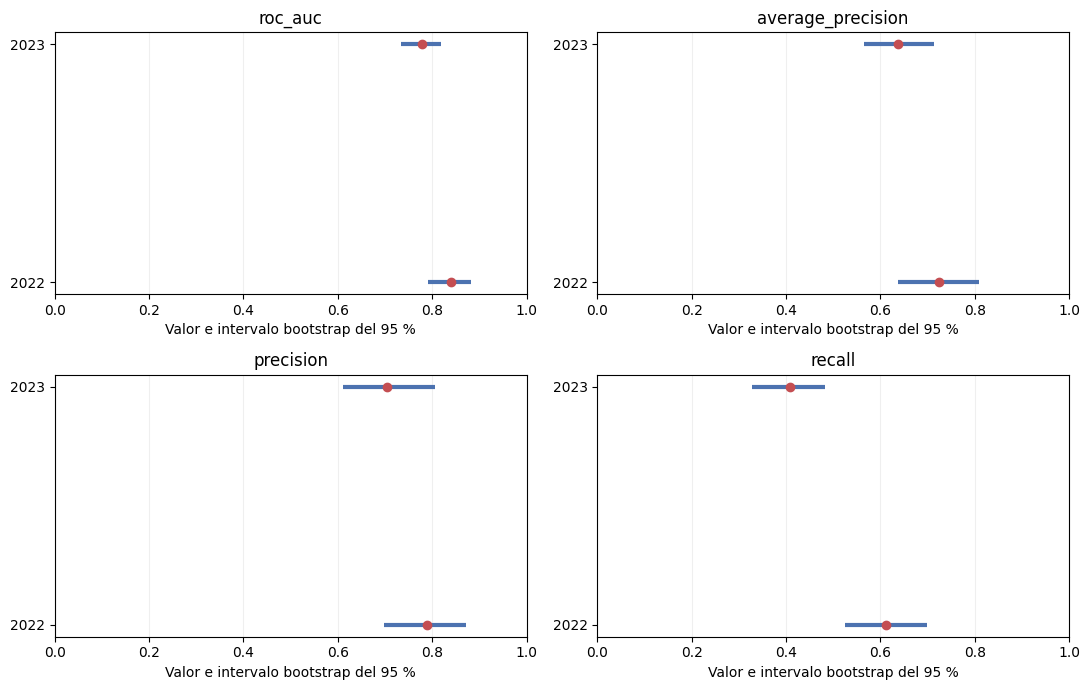

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, metrica in zip(
    axes.flat,
    ["roc_auc", "average_precision", "precision", "recall"],
):
    datos = metricas_finales.loc[
        metricas_finales["metrica"].eq(metrica)
    ].sort_values("anio_evaluacion")

    posiciones = np.arange(len(datos))

    ax.hlines(
        posiciones,
        datos["ic95_inferior"],
        datos["ic95_superior"],
        color="#4c72b0",
        linewidth=3,
    )
    ax.scatter(datos["valor"], posiciones, color="#c44e52", zorder=3)
    ax.set_yticks(posiciones, datos["anio_evaluacion"].astype(str))
    ax.set_xlim(0, 1)
    ax.set_title(metrica)
    ax.set_xlabel("Valor e intervalo bootstrap del 95 %")
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
figuras["metricas_intervalos_bootstrap.png"] = fig
plt.show()


## 6. Ajuste del pipeline para guardar

Se utiliza la candidata elegida sin recalibración adicional. Las edades originalmente inválidas se dejan faltantes para que el pipeline aprenda su imputación. El ajuste usa todos los registros etiquetados hasta 2023, cuyo seguimiento termina como máximo en 2025. Este ajuste no produce una nueva estimación de desempeño.


In [6]:
df_raw = load_raw()

edades_originales = df_raw[
    CLAVES + ["edad"]
].rename(columns={"edad": "edad_original"})

entrenamiento = df_modelado.merge(
    edades_originales,
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
).reset_index(drop=True)

assert entrenamiento["edad_original"].notna().all()
assert entrenamiento["abandono"].isin([0, 1]).all()
assert (
    entrenamiento["anio_academico"] + VENTANA
).le(CIERRE_DATOS).all()

entrenamiento["edad"] = entrenamiento["edad"].astype(float)
entrenamiento.loc[
    entrenamiento["edad_original"].eq(0), "edad"
] = np.nan

assert set(COLUMNAS_MODELO).issubset(entrenamiento.columns)
assert len(COLUMNAS_MODELO) == len(set(COLUMNAS_MODELO))
assert not {
    "id_alumno", "anio_academico", "abandono",
    "prox_actividad", "edad_original",
}.intersection(COLUMNAS_MODELO)

X_entrenamiento = entrenamiento[COLUMNAS_MODELO].copy()
y_entrenamiento = entrenamiento["abandono"].astype(int)

assert not np.isinf(X_entrenamiento.to_numpy(dtype=float)).any()

modelo_final = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        class_weight=None,
    )),
])

modelo_final.fit(X_entrenamiento, y_entrenamiento)

print("Registros de ajuste:", len(X_entrenamiento))
print("Estudiantes:", entrenamiento["id_alumno"].nunique())
print("Predictores:", len(COLUMNAS_MODELO))
print("No se calculan métricas sobre este entrenamiento.")


Registros de ajuste: 1979
Estudiantes: 1019
Predictores: 16
No se calculan métricas sobre este entrenamiento.


## 7. Predicciones de demostración al cierre de 2025

Se conserva únicamente el historial disponible hasta el cierre configurado antes de calcular las features. Se predicen las filas de ese año, sin construirles target. Sus resultados de los dos años siguientes no están completos y no se usan para evaluar. Esta tabla es una demostración local, no una escritura en la base de producción.


In [7]:
historial_cierre = df_raw.loc[
    df_raw["anio_academico"].le(CIERRE_DATOS)
].copy()

assert not historial_cierre.duplicated(CLAVES).any()

features_cierre = agregar_features(historial_cierre)
features_cierre["edad"] = features_cierre["edad"].astype(float)
features_cierre.loc[
    features_cierre["edad"].eq(0), "edad"
] = np.nan

df_scoring = (
    features_cierre.loc[
        features_cierre["anio_academico"].eq(CIERRE_DATOS)
    ]
    .sort_values("id_alumno")
    .reset_index(drop=True)
)

assert len(df_scoring) >= 3
assert df_scoring["id_alumno"].is_unique

X_scoring = df_scoring[COLUMNAS_MODELO].copy()
prob_scoring = modelo_final.predict_proba(X_scoring)[:, 1]

scoring_demostracion = df_scoring[CLAVES].copy()
scoring_demostracion["modelo_version"] = VERSION_MODELO
scoring_demostracion["probabilidad_abandono"] = prob_scoring
scoring_demostracion["alerta_referencia_050"] = (
    prob_scoring >= UMBRAL_REFERENCIA
).astype(int)
scoring_demostracion["primer_anio_seguimiento"] = CIERRE_DATOS + 1
scoring_demostracion["ultimo_anio_seguimiento"] = CIERRE_DATOS + VENTANA
scoring_demostracion["posicion"] = np.arange(len(df_scoring))

assert np.isfinite(prob_scoring).all()
assert scoring_demostracion["probabilidad_abandono"].between(0, 1).all()

print("Observaciones de demostración:", len(scoring_demostracion))
display(
    scoring_demostracion.sort_values(
        "probabilidad_abandono", ascending=False
    ).head(10)
)


Observaciones de demostración: 663


/Users/alejo/Desktop/alerta-temprana-desercion/src/features/build_features.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ritmo_vs_plan"] = (df["porcentaje_avance_carrera"] / ritmo_teorico).fillna(0)


,id_alumno,anio_academico,modelo_version,probabilidad_abandono,alerta_referencia_050,primer_anio_seguimiento,ultimo_anio_seguimiento,posicion
592,1312,2025,logistica-recuentos-v1,0.853091,1,2026,2027,592
623,1345,2025,logistica-recuentos-v1,0.819410,1,2026,2027,623
608,1330,2025,logistica-recuentos-v1,0.805338,1,2026,2027,608
486,1195,2025,logistica-recuentos-v1,0.804321,1,2026,2027,486
584,1302,2025,logistica-recuentos-v1,0.801834,1,2026,2027,584
582,1300,2025,logistica-recuentos-v1,0.788297,1,2026,2027,582
578,1296,2025,logistica-recuentos-v1,0.788142,1,2026,2027,578
563,1281,2025,logistica-recuentos-v1,0.787679,1,2026,2027,563
573,1291,2025,logistica-recuentos-v1,0.786594,1,2026,2027,573
617,1339,2025,logistica-recuentos-v1,0.785972,1,2026,2027,617


## 8. SHAP lineal analítico en log-odds

Para el margen de una logística, los valores SHAP intervencionales bajo un fondo con variables independientes se calculan como coeficiente × (valor transformado − media del fondo). Se usa como fondo el entrenamiento final y se verifica que las contribuciones reconstruyan el margen y la probabilidad del pipeline. Las contribuciones se suman en log-odds, no en puntos porcentuales. Las variables están correlacionadas: la atribución depende de esta convención y no demuestra causalidad. La probabilidad del valor base tampoco es necesariamente la probabilidad media de la población. Referencia: [LinearExplainer de SHAP](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html).


In [8]:
preprocesador = modelo_final[:-1]
logistica_ajustada = modelo_final.named_steps["modelo"]

Z_entrenamiento = preprocesador.transform(X_entrenamiento)
Z_scoring = preprocesador.transform(X_scoring)

media_fondo = np.mean(Z_entrenamiento, axis=0)
coeficientes = logistica_ajustada.coef_[0]
intercepto = float(logistica_ajustada.intercept_[0])

shap_valores = (
    Z_scoring - media_fondo
) * coeficientes

valor_base_log_odds = float(
    intercepto + np.dot(media_fondo, coeficientes)
)

margen_reconstruido = (
    valor_base_log_odds + shap_valores.sum(axis=1)
)

np.testing.assert_allclose(
    margen_reconstruido,
    modelo_final.decision_function(X_scoring),
    atol=1e-10,
    rtol=1e-10,
)

np.testing.assert_allclose(
    expit(margen_reconstruido),
    prob_scoring,
    atol=1e-12,
    rtol=1e-10,
)

print("Reconstrucción del margen y la probabilidad: OK")
print("Valor base en log-odds:", round(valor_base_log_odds, 4))
print("Probabilidad del valor base:", round(float(expit(valor_base_log_odds)), 4))


Reconstrucción del margen y la probabilidad: OK
Valor base en log-odds: -1.2637
Probabilidad del valor base: 0.2203


## 9. Importancia global para las observaciones de demostración

Se ordenan las dieciséis features por la media del valor absoluto de su contribución. El gráfico describe el comportamiento del modelo sobre las filas de 2025; no es una nueva métrica de evaluación ni una relación causal.


,feature,shap_abs_medio_log_odds,coeficiente_estandarizado
0,porcentaje_avance_cursado,0.8059,-0.5204
1,tasa_aprobacion_asignaturas,0.7649,-0.7946
2,inscripciones_finales,0.7036,-0.4112
3,porcentaje_avance_carrera,0.6924,-0.5045
4,finales_aprobados,0.4519,0.2575
5,asignaturas_cursadas,0.4390,-0.2185
6,ritmo_vs_plan,0.1827,-0.2003
7,tasa_desaprobacion_asignaturas,0.1695,-0.2564
8,brecha_cursado_carrera,0.1647,-0.0781
9,anios_sin_finales,0.0864,-0.1151


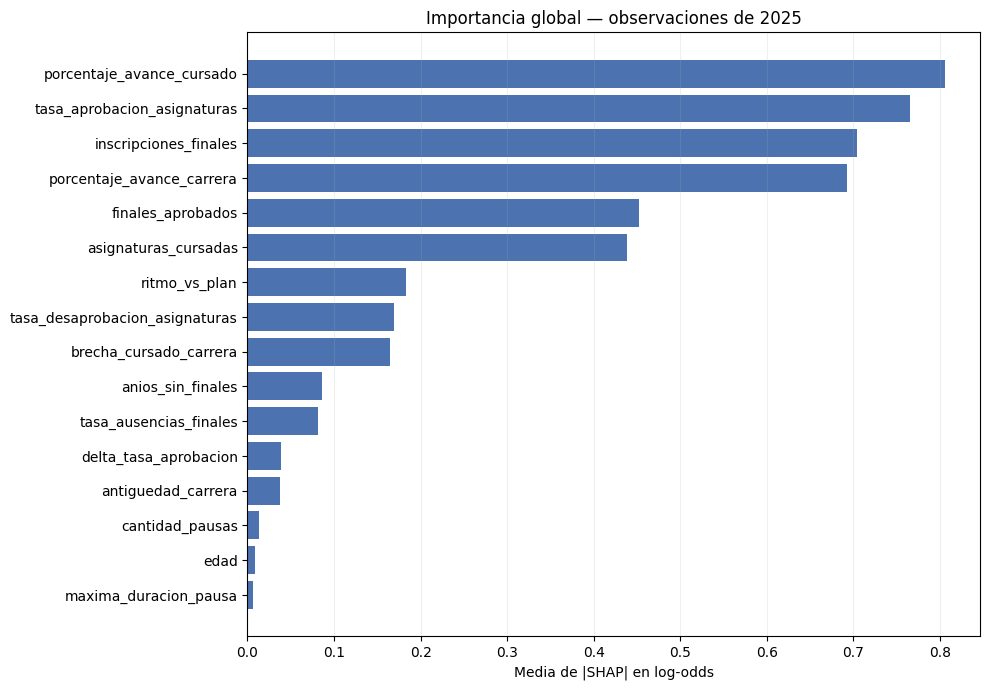

In [9]:
importancia_global = pd.DataFrame({
    "feature": COLUMNAS_MODELO,
    "shap_abs_medio_log_odds": np.abs(shap_valores).mean(axis=0),
    "coeficiente_estandarizado": coeficientes,
}).sort_values(
    "shap_abs_medio_log_odds",
    ascending=False,
).reset_index(drop=True)

display(importancia_global.round(4))

datos_grafico = importancia_global.sort_values(
    "shap_abs_medio_log_odds"
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    datos_grafico["feature"],
    datos_grafico["shap_abs_medio_log_odds"],
    color="#4c72b0",
)
ax.set_xlabel("Media de |SHAP| en log-odds")
ax.set_title(f"Importancia global — observaciones de {CIERRE_DATOS}")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
figuras["shap_importancia_global.png"] = fig
plt.show()


## 10. Selección de tres casos individuales

Se eligen puntuaciones baja, intermedia y alta dentro de la demostración. Son posiciones relativas en la distribución, no bandas de riesgo validadas. Se guardan el valor de entrada, el valor imputado usado y la contribución de cada feature.


In [10]:
ordenados = scoring_demostracion.sort_values(
    ["probabilidad_abandono", "id_alumno"],
    ascending=[True, True],
)

posiciones_relativas = [
    (0, "bajo_relativo"),
    (len(ordenados) // 2, "intermedio_relativo"),
    (len(ordenados) - 1, "alto_relativo"),
]

casos = []
filas_explicaciones = []
X_scoring_imputado = modelo_final.named_steps["imputacion"].transform(
    X_scoring
)

for posicion_relativa, perfil in posiciones_relativas:
    caso = ordenados.iloc[posicion_relativa]
    posicion = int(caso["posicion"])

    casos.append({
        "id_alumno": int(caso["id_alumno"]),
        "anio_academico": int(caso["anio_academico"]),
        "perfil_relativo": perfil,
        "probabilidad_abandono": float(caso["probabilidad_abandono"]),
        "valor_base_log_odds": valor_base_log_odds,
        "suma_contribuciones_log_odds": float(
            shap_valores[posicion].sum()
        ),
        "margen_log_odds": float(margen_reconstruido[posicion]),
        "posicion": posicion,
    })

    for j, feature in enumerate(COLUMNAS_MODELO):
        contribucion = float(shap_valores[posicion, j])

        filas_explicaciones.append({
            "id_alumno": int(caso["id_alumno"]),
            "anio_academico": int(caso["anio_academico"]),
            "perfil_relativo": perfil,
            "feature": feature,
            "valor_entrada": float(X_scoring.iloc[posicion, j]),
            "valor_usado": float(X_scoring_imputado[posicion, j]),
            "shap_log_odds": contribucion,
            "efecto": (
                "aumenta_margen" if contribucion > 0
                else "reduce_margen" if contribucion < 0
                else "sin_contribucion"
            ),
        })

casos_explicados = pd.DataFrame(casos)
explicaciones_casos = pd.DataFrame(filas_explicaciones)

assert casos_explicados["id_alumno"].nunique() == 3
assert len(explicaciones_casos) == 3 * len(COLUMNAS_MODELO)

display(casos_explicados.round(4))
display(
    explicaciones_casos.assign(
        magnitud=lambda x: x["shap_log_odds"].abs()
    )
    .sort_values(
        ["id_alumno", "magnitud"], ascending=[True, False]
    )
    .groupby("id_alumno", sort=False)
    .head(5)
    .drop(columns="magnitud")
    .round(4)
)


,id_alumno,anio_academico,perfil_relativo,probabilidad_abandono,valor_base_log_odds,suma_contribuciones_log_odds,margen_log_odds,posicion
0,595,2025,bajo_relativo,0.0002,-1.2637,-7.4711,-8.7348,169
1,632,2025,intermedio_relativo,0.0226,-1.2637,-2.5036,-3.7673,188
2,1312,2025,alto_relativo,0.8531,-1.2637,3.0227,1.7591,592


,id_alumno,anio_academico,perfil_relativo,feature,valor_entrada,valor_usado,shap_log_odds,efecto
14,595,2025,bajo_relativo,inscripciones_finales,16.000,16.000,-2.6138,reduce_margen
4,595,2025,bajo_relativo,porcentaje_avance_cursado,0.896,0.896,-2.2103,reduce_margen
3,595,2025,bajo_relativo,porcentaje_avance_carrera,0.750,0.750,-1.6949,reduce_margen
15,595,2025,bajo_relativo,finales_aprobados,11.000,11.000,1.2490,aumenta_margen
13,595,2025,bajo_relativo,asignaturas_cursadas,12.000,12.000,-0.9099,reduce_margen
19,632,2025,intermedio_relativo,porcentaje_avance_carrera,0.500,0.500,-0.9265,reduce_margen
20,632,2025,intermedio_relativo,porcentaje_avance_cursado,0.479,0.479,-0.8857,reduce_margen
16,632,2025,intermedio_relativo,tasa_aprobacion_asignaturas,0.830,0.830,-0.6074,reduce_margen
30,632,2025,intermedio_relativo,inscripciones_finales,5.000,5.000,-0.5081,reduce_margen
31,632,2025,intermedio_relativo,finales_aprobados,5.000,5.000,0.4330,aumenta_margen


## 11. Gráficos de los tres casos

Una contribución positiva aumenta el margen respecto del valor base y una negativa lo reduce. Los valores no son porcentajes y no permiten inferir efectos causales de una intervención.


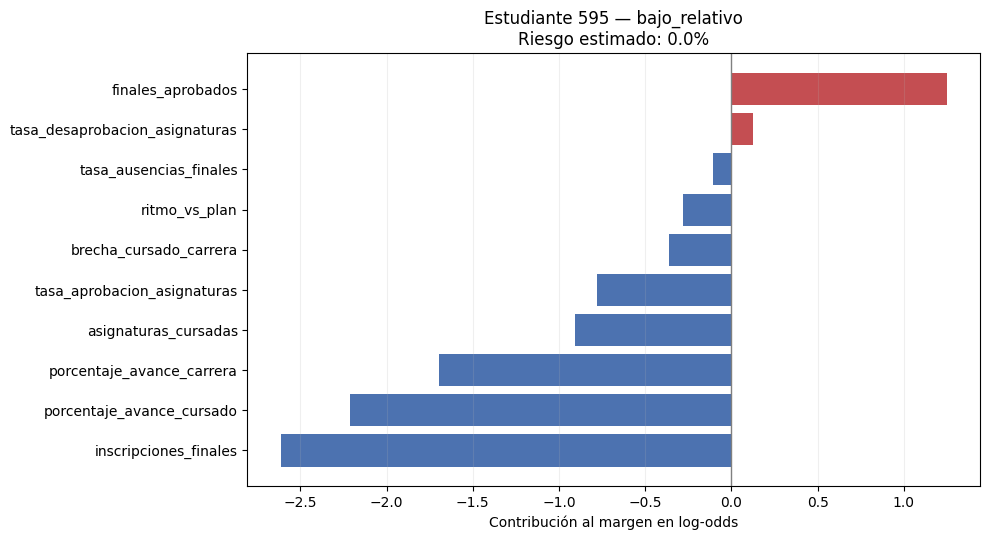

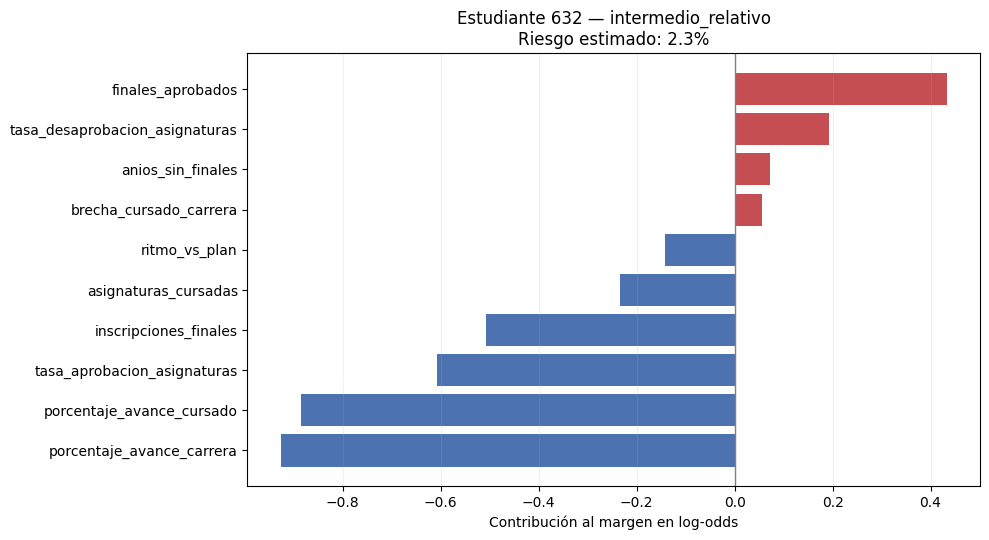

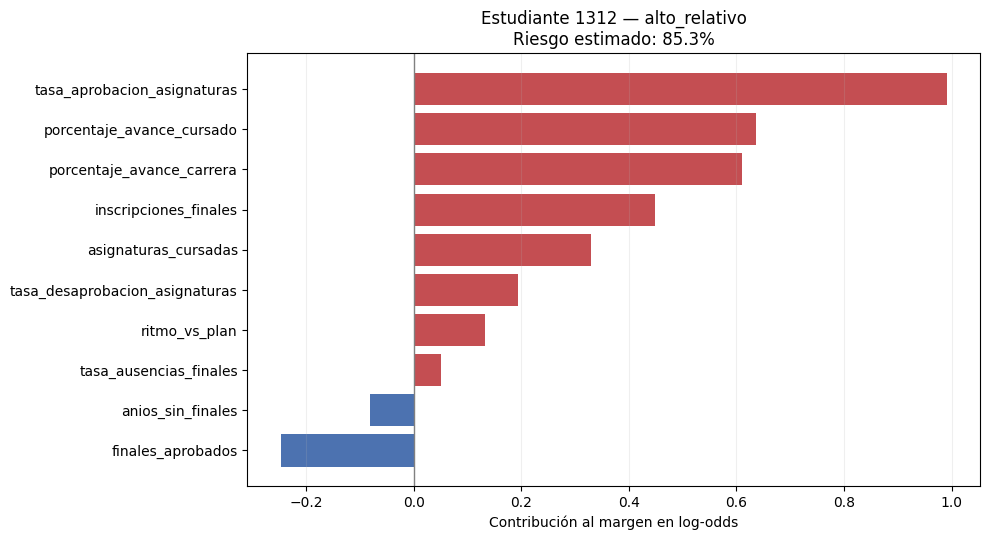

In [11]:
for caso in casos_explicados.to_dict("records"):
    datos = explicaciones_casos.loc[
        explicaciones_casos["id_alumno"].eq(caso["id_alumno"])
    ].copy()

    datos = (
        datos.assign(magnitud=datos["shap_log_odds"].abs())
        .nlargest(10, "magnitud")
        .sort_values("shap_log_odds")
    )

    colores = np.where(
        datos["shap_log_odds"].ge(0),
        "#c44e52",
        "#4c72b0",
    )

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.barh(
        datos["feature"],
        datos["shap_log_odds"],
        color=colores,
    )
    ax.axvline(0, color="gray", linewidth=1)
    ax.set_xlabel("Contribución al margen en log-odds")
    ax.set_title(
        f"Estudiante {caso['id_alumno']} — {caso['perfil_relativo']}\n"
        f"Riesgo estimado: {caso['probabilidad_abandono']:.1%}"
    )
    ax.grid(axis="x", alpha=0.2)

    plt.tight_layout()
    figuras[f"shap_caso_{caso['perfil_relativo']}.png"] = fig
    plt.show()


## 12. Guardado del paquete y los artefactos locales

Se guarda el pipeline completo con las claves modelo y features utilizadas por el cargador existente. Esto no completa la integración de producción: el entrenamiento automatizado, la API, la carga del historial y el batch todavía deben alinearse con la logística y sus dieciséis entradas, incluida inscripciones_finales. El corte y las bandas no se declaran validados. Las versiones del entorno quedan registradas para reproducir el modelo. Referencia: [persistencia de modelos en scikit-learn](https://scikit-learn.org/stable/model_persistence.html).


In [12]:
def sha256_archivo(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


metadatos_modelo = {
    "version": VERSION_MODELO,
    "modelo": "logistica_recuentos",
    "estado": "prototipo_evaluado_exploratoriamente",
    "features": COLUMNAS_MODELO,
    "calibracion": "sin_recalibracion_adicional",
    "umbral_referencia": UMBRAL_REFERENCIA,
    "umbral_validado": False,
    "bandas_riesgo_validadas": False,
    "target": {
        "ventana_anios": VENTANA,
        "cierre_seguimiento": CIERRE_DATOS,
    },
    "entrenamiento": {
        "registros": len(entrenamiento),
        "estudiantes": int(entrenamiento["id_alumno"].nunique()),
        "positivos": int(y_entrenamiento.sum()),
        "primer_anio": int(entrenamiento["anio_academico"].min()),
        "ultimo_anio": int(entrenamiento["anio_academico"].max()),
    },
    "evaluacion": {
        "tipo": "temporal_y_por_estudiante_exploratoria",
        "anios": ANIOS_EVALUACION,
        "bootstrap": N_BOOTSTRAP,
        "nivel_confianza": NIVEL_CONFIANZA,
        "semilla": SEED,
        "reentrena_en_bootstrap": False,
    },
    "explicabilidad": {
        "metodo": "shap_lineal_intervencional_analitico",
        "escala": "log_odds",
        "supuesto": "fondo_con_variables_independientes",
        "media_fondo_transformado": media_fondo.tolist(),
        "valor_base_log_odds": valor_base_log_odds,
    },
    "huellas": {
        "dataset_modelado_sha256": sha256_archivo(
            PROJ_ROOT / "data/processed/dataset_modelado.parquet"
        ),
        "predicciones_evaluacion_sha256": sha256_archivo(ruta_predicciones),
        "config_sha256": sha256_archivo(PROJ_ROOT / "configs/config.yaml"),
    },
    "versiones": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "joblib": joblib.__version__,
    },
}

paquete_modelo = {
    "modelo": modelo_final,
    "features": COLUMNAS_MODELO,
    "metadata": metadatos_modelo,
}

CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

reportes = {
    "metricas_finales.csv": metricas_finales,
    "bootstrap_metricas_finales.csv": muestras_bootstrap,
    "shap_importancia_global.csv": importancia_global,
    "shap_casos_individuales.csv": explicaciones_casos,
    "casos_explicados.csv": casos_explicados,
    "scoring_demostracion.csv": scoring_demostracion.drop(
        columns="posicion"
    ),
}

for nombre, tabla in reportes.items():
    tabla.to_csv(CARPETA_REPORTES / nombre, index=False)

with open(
    CARPETA_REPORTES / "modelo_final_metadata.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(metadatos_modelo, archivo, ensure_ascii=False, indent=2)

for nombre, figura in figuras.items():
    figura.savefig(
        CARPETA_FIGURAS / nombre,
        dpi=160,
        bbox_inches="tight",
    )

joblib.dump(paquete_modelo, RUTA_MODELO)

print("Modelo guardado en:", RUTA_MODELO)
print("CSV y metadatos guardados en:", CARPETA_REPORTES)
print("Figuras guardadas en:", CARPETA_FIGURAS)
print("No se realizó ninguna publicación ni despliegue.")


Modelo guardado en: /Users/alejo/Desktop/alerta-temprana-desercion/models/modelo_final.joblib
CSV y metadatos guardados en: /Users/alejo/Desktop/alerta-temprana-desercion/reports
Figuras guardadas en: /Users/alejo/Desktop/alerta-temprana-desercion/reports/figures
No se realizó ninguna publicación ni despliegue.


## 13. Comprobación de recarga

Se carga únicamente el archivo generado por este cuaderno y se comprueba que conserva las predicciones. El paquete usa estimadores estándar y no depende de funciones definidas dentro del notebook para predecir. La integración con la API y Railway se realiza después, con las mismas entradas y versiones compatibles.


In [13]:
paquete_recargado = joblib.load(RUTA_MODELO)

assert paquete_recargado["features"] == COLUMNAS_MODELO
assert paquete_recargado["metadata"]["version"] == VERSION_MODELO

prob_recargadas = paquete_recargado["modelo"].predict_proba(
    X_scoring[paquete_recargado["features"]]
)[:, 1]

np.testing.assert_allclose(
    prob_recargadas,
    prob_scoring,
    atol=1e-12,
    rtol=1e-12,
)

print("Recarga verificada: mismas probabilidades.")
print("La evaluación temporal permanece separada del ajuste final.")


Recarga verificada: mismas probabilidades.
La evaluación temporal permanece separada del ajuste final.


## Conclusiones del cierre

Se conserva la logística con recuentos sin recalibración adicional. Las cifras siguientes proceden de predicciones temporales fuera de muestra; los intervalos son percentiles bootstrap del 95 % por estudiante.

| Año | ROC-AUC [IC 95 %] | Average Precision [IC 95 %] | Recall a 0,50 [IC 95 %] |
|---|---|---|---|
| 2022 | 0,8410 [0,7917; 0,8828] | 0,7246 [0,6381; 0,8099] | 61,21 % [52,57 %; 69,83 %] |
| 2023 | 0,7782 [0,7341; 0,8187] | 0,6381 [0,5648; 0,7133] | 40,79 % [32,89 %; 48,24 %] |

- **La limitación operativa permanece:** con corte 0,50 no se detecta a la mayoría de los positivos de 2023. Los intervalos no corrigen esa dificultad ni garantizan desempeño futuro.
- **Explicabilidad:** en las 663 observaciones de demostración de 2025, las mayores contribuciones absolutas medias corresponden a avance de cursado, tasa de aprobación e inscripciones a finales. Se explicaron tres perfiles relativos. Los valores SHAP son analíticos en log-odds bajo un supuesto de independencia, no efectos causales ni puntos porcentuales.
- **Artefacto reproducible:** se prepara un pipeline con imputación, escalado y logística, ajustado con 1.979 registros de 1.019 estudiantes y dieciséis predictores. La recarga conserva las probabilidades.
- **Alcance:** las métricas no proceden del ajuste final. El bootstrap mantiene fijas las predicciones y no incluye toda la incertidumbre de selección o entrenamiento. Los años inspeccionados no son un test independiente.

El cierre corresponde a un prototipo local. Quedan por alinear entrenamiento, API, carga de datos y batch con las dieciséis entradas antes de publicar, además de confirmar el criterio de alerta. El corte y las bandas siguen sin validación operativa. Las observaciones de 2025 se puntúan para 2026–2027 y no tienen aquí un resultado verificado.
